# Results

Every model was trained on all pets with identical settings; here they're evaluated on the held-out
test split (1,181 cats, 2,481 dogs), with and without horizontal-flip test-time augmentation (TTA).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from torch.utils.data import DataLoader

from manet_lib import (
    read_pet_list, PetSegDataset, build_model, count_params, predict_dataset, predict_probs,
    predict_image, per_image_scores, denormalize, overlay, mask_outline,
)

ROOT = Path("data/oxford-iiit-pet")
MY_CATS = Path("my_cats")
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
THRESH = 0.5
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

RUNS = {
    "Basic CNN (80 ep)": ("checkpoints/basiccnn_e80_pets_best.pt", "outputs/basiccnn_e80_history.csv"),
    "MANet (40 ep)":     ("checkpoints/manet_e40_pets_best.pt",    "outputs/manet_e40_history.csv"),
    "MANet (80 ep)":     ("checkpoints/manet_e80_lr3e-4_pets_best.pt", "outputs/manet_e80_lr3e-4_history.csv"),
}
BASELINE, BEST = "Basic CNN (80 ep)", "MANet (80 ep)"

models, info = {}, []
for run, (ckpt_path, _) in RUNS.items():
    ckpt = torch.load(ckpt_path, map_location=device)
    m = build_model(ckpt["model_name"]).to(device)
    m.load_state_dict(ckpt["model"]); m.eval()
    models[run] = m
    info.append({"run": run, "model": ckpt["model_name"], "params (M)": round(count_params(m) / 1e6, 2),
                 "best epoch": ckpt["epoch"], "val Dice": round(ckpt["val_dice"], 4)})
IMG_SIZE = ckpt["img_size"]
pd.DataFrame(info).set_index("run")

,model,params (M),best epoch,val Dice
run,,,,
Basic CNN (80 ep),BasicCNN,0.28,75,0.8329
MANet (40 ep),MANet,33.40,38,0.8917
MANet (80 ep),MANet,33.40,71,0.9352


## Test-set evaluation: every model, with and without flip TTA

In [2]:
test_rows = read_pet_list(ROOT, "test")
test_ds = PetSegDataset(ROOT, test_rows, IMG_SIZE, train=False)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=6, pin_memory=True)

frames = []
for run, m in models.items():
    for tta in (False, True):
        df = pd.DataFrame(predict_dataset(m, test_loader, device=device, threshold=THRESH, tta=tta))
        frames.append(df.assign(run=run, tta=tta))
        print(f"{run:18s} tta={tta!s:5s}  mean Dice {df[df.gt_frac > 0].dice.mean():.4f}")
res_all = pd.concat(frames, ignore_index=True)
res_all.to_csv(OUT_DIR / "test_predictions_all_models.csv", index=False)

# A few Oxford-IIIT Pet trimaps are broken (every pixel marked background); they score
# Dice 0 whatever the model does, so they're excluded from all metrics below.
empty = sorted(res_all.loc[res_all.gt_frac == 0, "name"].unique())
print(f"\nExcluding {len(empty)} test images with empty ground-truth masks: {empty}")
res = res_all[res_all.gt_frac > 0].reset_index(drop=True)

Basic CNN (80 ep)  tta=False  mean Dice 0.8408


Basic CNN (80 ep)  tta=True   mean Dice 0.8445


MANet (40 ep)      tta=False  mean Dice 0.9017


MANet (40 ep)      tta=True   mean Dice 0.9039


MANet (80 ep)      tta=False  mean Dice 0.9419


MANet (80 ep)      tta=True   mean Dice 0.9434

Excluding 7 test images with empty ground-truth masks: ['Egyptian_Mau_20', 'Persian_259', 'japanese_chin_199', 'keeshond_7', 'saint_bernard_60', 'saint_bernard_78', 'wheaten_terrier_195']


In [3]:
table = (res.groupby(["run", "tta", "species"])[["dice", "iou", "acc"]].mean()
           .unstack("species").round(4))
table = table.reindex(list(RUNS), level="run")
table

dice             iou             acc        
species                     cat     dog     cat     dog     cat     dog
run               tta                                                  
Basic CNN (80 ep) False  0.8369  0.8426  0.7345  0.7446  0.8603  0.8829
                  True   0.8401  0.8466  0.7393  0.7506  0.8630  0.8860
MANet (40 ep)     False  0.8955  0.9046  0.8233  0.8361  0.9125  0.9312
                  True   0.8969  0.9073  0.8257  0.8401  0.9139  0.9328
MANet (80 ep)     False  0.9352  0.9451  0.8870  0.8998  0.9478  0.9615
                  True   0.9371  0.9463  0.8899  0.9018  0.9493  0.9624

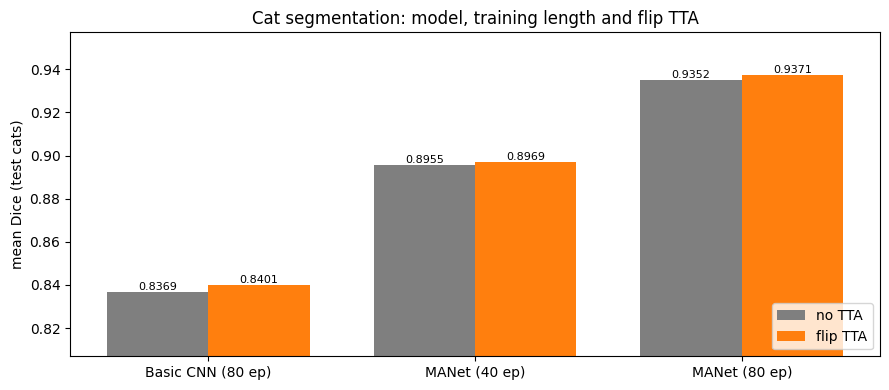

,TTA gain (cat Dice)
run,
Basic CNN (80 ep),0.0032
MANet (40 ep),0.0014
MANet (80 ep),0.0020


In [4]:
cat_tbl = res[res.species == "cat"].groupby(["run", "tta"])["dice"].mean().unstack("tta").reindex(list(RUNS))
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(cat_tbl)); w = 0.38
b1 = ax.bar(x - w / 2, cat_tbl[False], w, label="no TTA", color="tab:gray")
b2 = ax.bar(x + w / 2, cat_tbl[True], w, label="flip TTA", color="tab:orange")
ax.bar_label(b1, fmt="%.4f", fontsize=8); ax.bar_label(b2, fmt="%.4f", fontsize=8)
ax.set_xticks(x, cat_tbl.index); ax.set_ylabel("mean Dice (test cats)")
ax.set_ylim(cat_tbl.values.min() - 0.03, min(1.0, cat_tbl.values.max() + 0.02))
ax.set_title("Cat segmentation: model, training length and flip TTA"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(OUT_DIR / "03_model_comparison.png", dpi=110); plt.show()

gain = (cat_tbl[True] - cat_tbl[False]).rename("TTA gain (cat Dice)")
gain.to_frame().round(4)

## Validation curves: basic CNN vs MANet

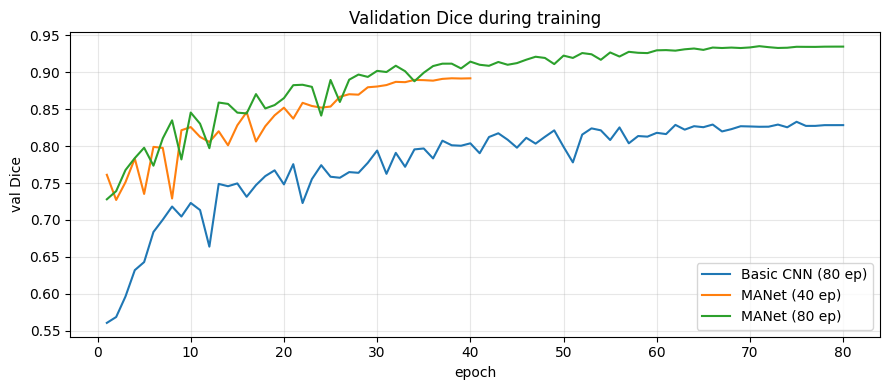

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
for run, (_, hist_path) in RUNS.items():
    h = pd.read_csv(hist_path)
    ax.plot(h.epoch, h.val_dice, label=run)
ax.set_xlabel("epoch"); ax.set_ylabel("val Dice"); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Validation Dice during training")
plt.tight_layout(); plt.savefig(OUT_DIR / "03_val_curves.png", dpi=110); plt.show()

## Comparing MANet and CNN

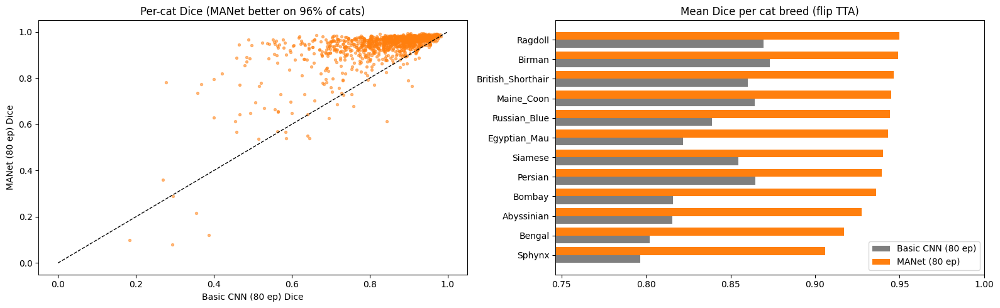

Mean gain +0.0970 Dice; median +0.0769


In [6]:
cats_tta = res[(res.species == "cat") & res.tta]
paired = cats_tta.pivot_table(index=["name", "breed"], columns="run", values="dice").reset_index()
paired["gain"] = paired[BEST] - paired[BASELINE]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].scatter(paired[BASELINE], paired[BEST], s=8, alpha=0.5, color="tab:orange")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel(f"{BASELINE} Dice"); axes[0].set_ylabel(f"{BEST} Dice")
axes[0].set_title(f"Per-cat Dice (MANet better on {(paired.gain > 0).mean():.0%} of cats)")

by_breed = paired.groupby("breed")[[BASELINE, BEST]].mean().sort_values(BEST)
y = np.arange(len(by_breed)); h = 0.4
axes[1].barh(y - h / 2, by_breed[BASELINE], h, label=BASELINE, color="tab:gray")
axes[1].barh(y + h / 2, by_breed[BEST], h, label=BEST, color="tab:orange")
axes[1].set_yticks(y, by_breed.index); axes[1].set_xlim(by_breed.values.min() - 0.05, 1.0)
axes[1].set_title("Mean Dice per cat breed (flip TTA)"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.savefig(OUT_DIR / "03_cnn_vs_manet_breeds.png", dpi=110); plt.show()

print(f"Mean gain {paired.gain.mean():+.4f} Dice; median {paired.gain.median():+.4f}")

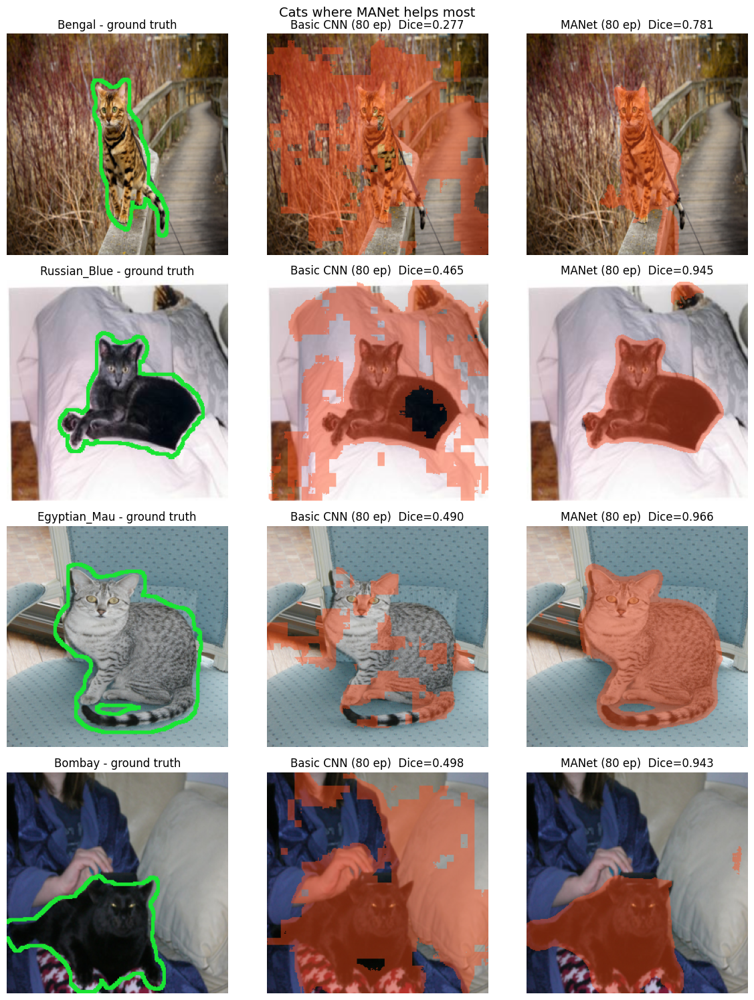

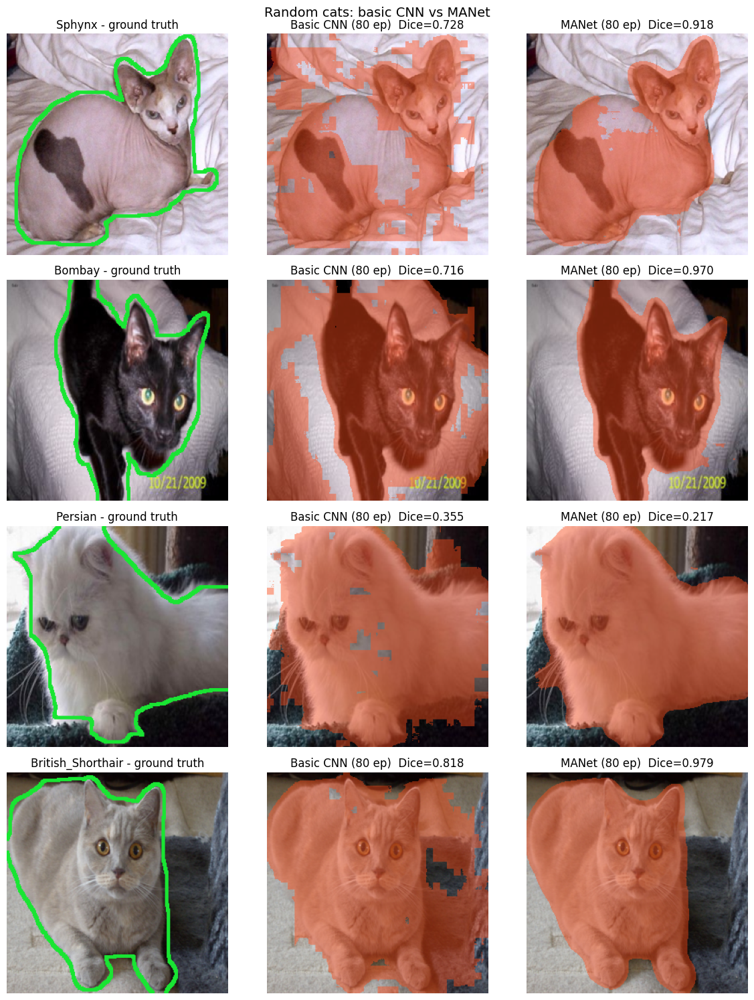

In [7]:
cat_ds = PetSegDataset(ROOT, [r for r in test_rows if r["species"] == "cat"], IMG_SIZE, train=False)
cat_index = {r["name"]: i for i, r in enumerate(cat_ds.rows)}
dice_lookup = cats_tta.set_index(["run", "name"])["dice"]

def cat_pred(run, name, tta=True):
    x, y, meta = cat_ds[cat_index[name]]
    prob = predict_probs(models[run], x[None].to(device), tta=tta)[0, 0].cpu().numpy()
    return x, y[0].numpy() > 0.5, prob, meta

def show_side_by_side(names, title, fname):
    fig, axes = plt.subplots(len(names), 3, figsize=(12, 3.8 * len(names)), squeeze=False)
    for row, name in zip(axes, names):
        x, gt, _, meta = cat_pred(BEST, name)
        img = denormalize(x)
        g = img.copy(); g[mask_outline(gt)] = (0.1, 0.9, 0.2)
        row[0].imshow(g); row[0].set_title(f"{meta['breed']} - ground truth")
        for ax, run in zip(row[1:], (BASELINE, BEST)):
            _, _, prob, _ = cat_pred(run, name)
            ax.imshow(overlay(img, prob > THRESH)); ax.set_title(f"{run}  Dice={dice_lookup[(run, name)]:.3f}")
        for a in row: a.axis("off")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=100); plt.show()

show_side_by_side(paired.sort_values("gain", ascending=False).name[:4].tolist(),
                  "Cats where MANet helps most", "03_manet_helps_most.png")
show_side_by_side(paired.sample(4, random_state=0).name.tolist(),
                  "Random cats: basic CNN vs MANet", "03_cnn_vs_manet_random.png")

## MANET results


Cats: 1181 images, 12 breeds
Mean Dice 0.9371 | median 0.9601 | mean IoU 0.8899 | pixel acc 0.9493
Cats with Dice < 0.8: 56 (4.7%)


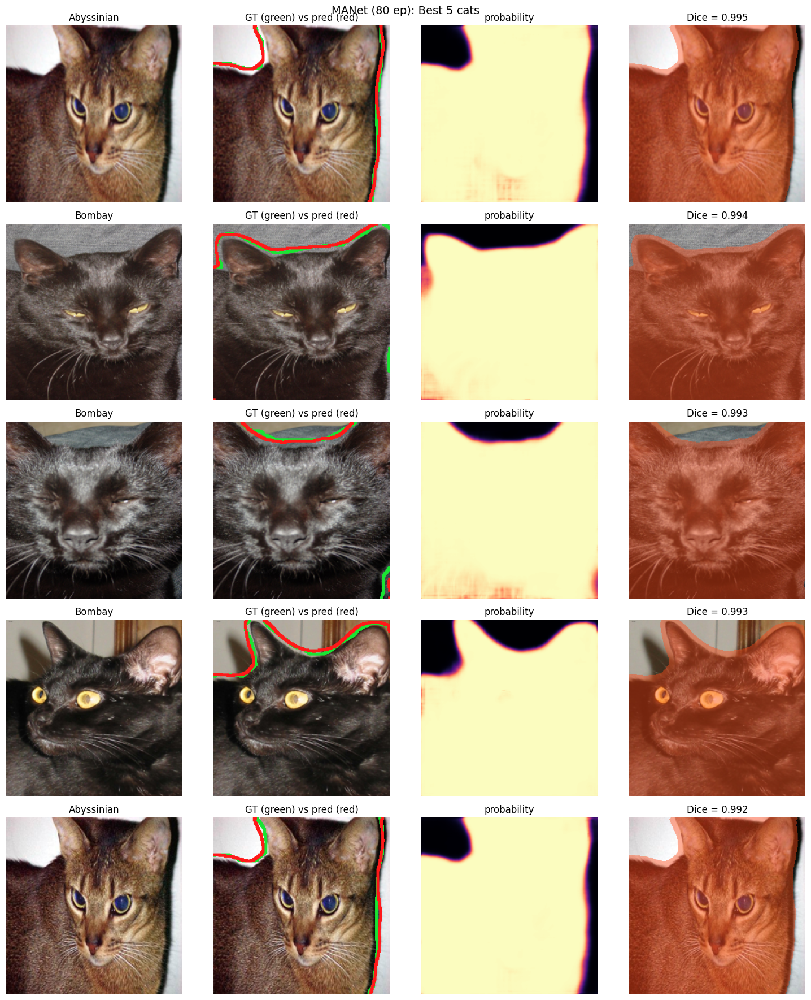

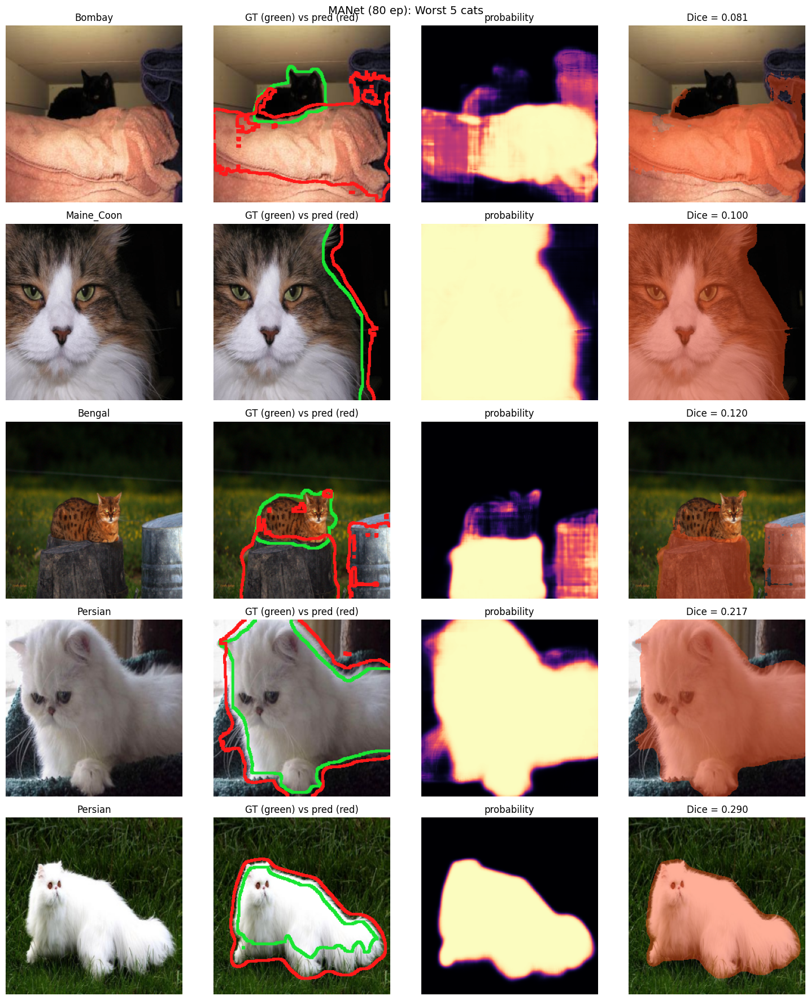

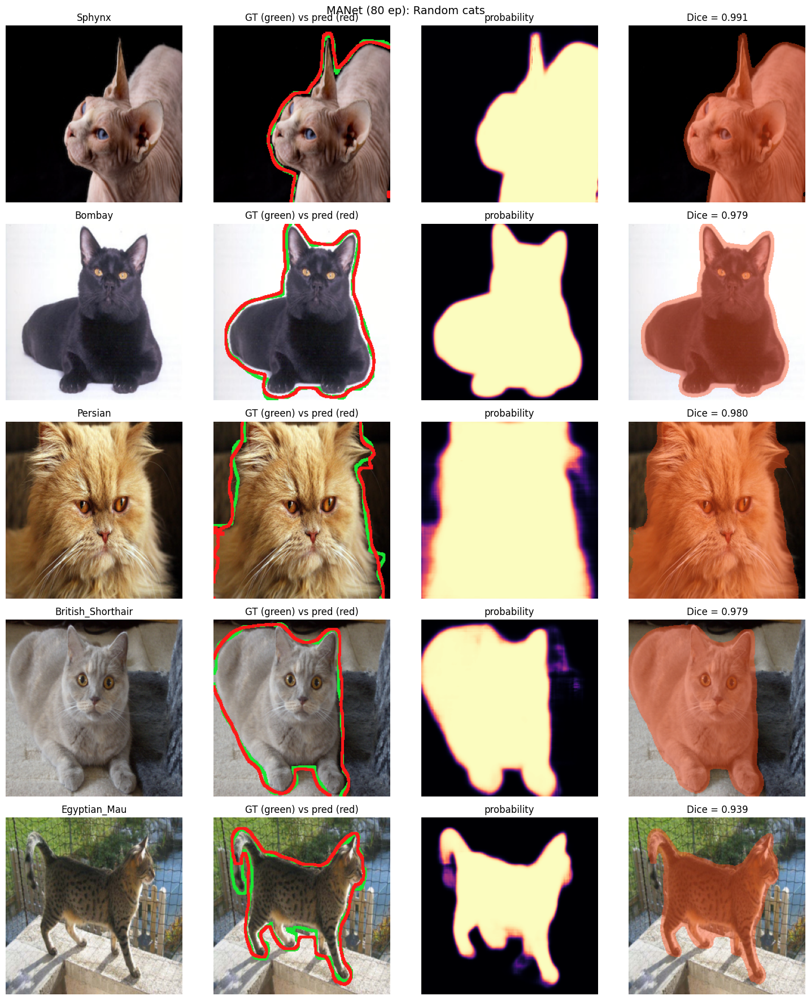

In [8]:
model = models[BEST]
cats = cats_tta[cats_tta.run == BEST]
print(f"Cats: {len(cats)} images, {cats.breed.nunique()} breeds")
print(f"Mean Dice {cats.dice.mean():.4f} | median {cats.dice.median():.4f} | mean IoU {cats.iou.mean():.4f} | pixel acc {cats.acc.mean():.4f}")
print(f"Cats with Dice < 0.8: {(cats.dice < 0.8).sum()} ({(cats.dice < 0.8).mean():.1%})")

def show_cats(names, title, fname, run=BEST):
    fig, axes = plt.subplots(len(names), 4, figsize=(15, 3.6 * len(names)))
    for row, name in zip(axes, names):
        x, gt, prob, meta = cat_pred(run, name)
        pred = prob > THRESH
        img = denormalize(x)
        outl = img.copy()
        outl[mask_outline(gt)] = (0.1, 0.9, 0.2)
        outl[mask_outline(pred)] = (1.0, 0.1, 0.1)
        row[0].imshow(img); row[0].set_title(meta["breed"])
        row[1].imshow(outl); row[1].set_title("GT (green) vs pred (red)")
        row[2].imshow(prob, cmap="magma", vmin=0, vmax=1); row[2].set_title("probability")
        row[3].imshow(overlay(img, pred)); row[3].set_title(f"Dice = {dice_lookup[(run, name)]:.3f}")
        for a in row: a.axis("off")
    fig.suptitle(f"{run}: {title}", fontsize=14)
    plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=100); plt.show()

ranked = cats.sort_values("dice")
show_cats(ranked.name.iloc[::-1][:5].tolist(), "Best 5 cats", "03_best_cats.png")
show_cats(ranked.name[:5].tolist(), "Worst 5 cats", "03_worst_cats.png")
show_cats(cats.sample(5, random_state=0).name.tolist(), "Random cats", "03_random_cats.png")

## CNN Results

Mean Dice 0.8401 | median 0.8714 | mean IoU 0.7393 | pixel acc 0.8630
Cats with Dice < 0.8: 314 (26.6%)


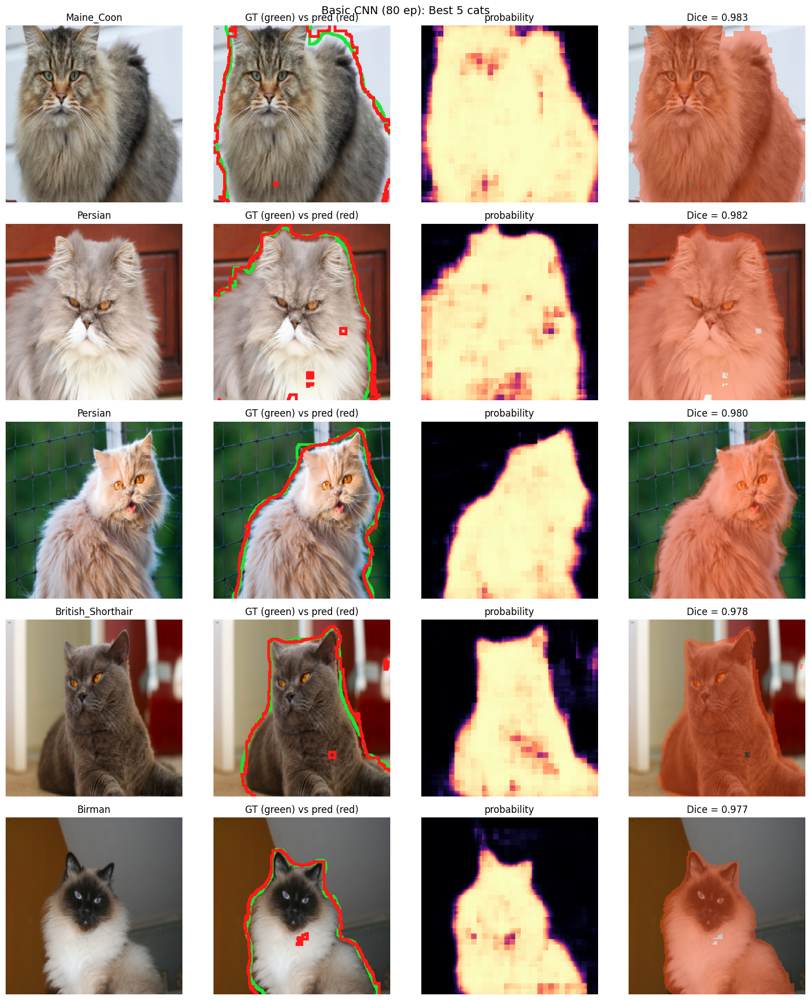

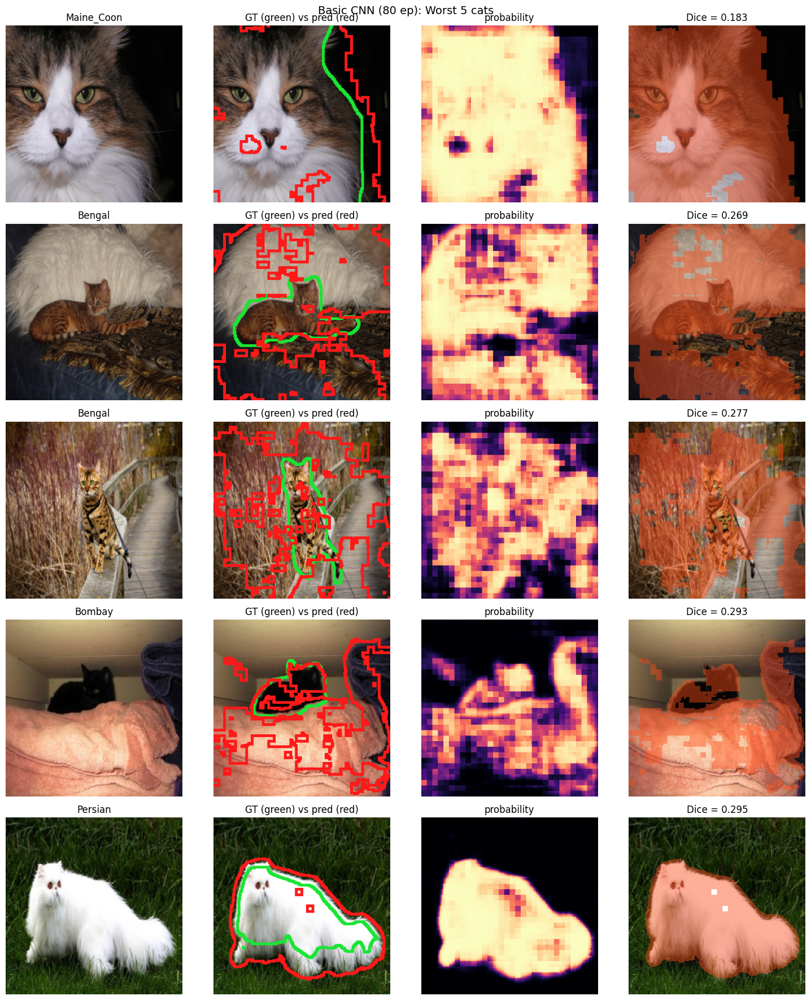

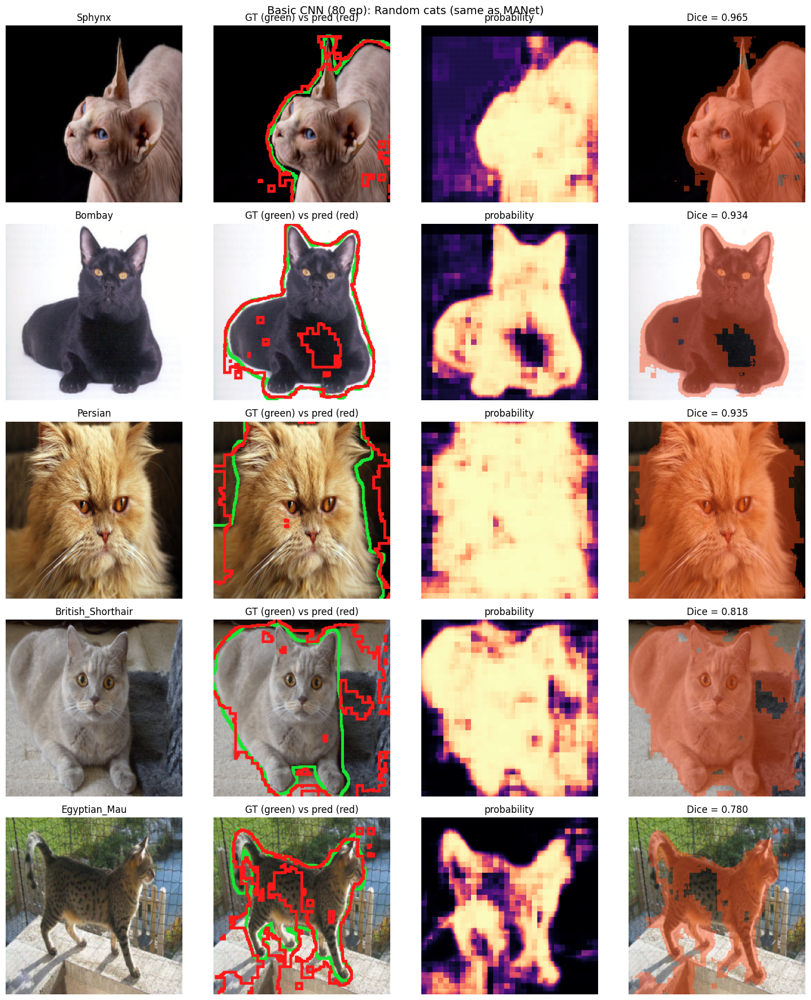

In [9]:
cnn_cats = cats_tta[cats_tta.run == BASELINE]
print(f"Mean Dice {cnn_cats.dice.mean():.4f} | median {cnn_cats.dice.median():.4f} | mean IoU {cnn_cats.iou.mean():.4f} | pixel acc {cnn_cats.acc.mean():.4f}")
print(f"Cats with Dice < 0.8: {(cnn_cats.dice < 0.8).sum()} ({(cnn_cats.dice < 0.8).mean():.1%})")

cnn_ranked = cnn_cats.sort_values("dice")
show_cats(cnn_ranked.name.iloc[::-1][:5].tolist(), "Best 5 cats", "03_cnn_best_cats.png", run=BASELINE)
show_cats(cnn_ranked.name[:5].tolist(), "Worst 5 cats", "03_cnn_worst_cats.png", run=BASELINE)
show_cats(cats.sample(5, random_state=0).name.tolist(), "Random cats (same as MANet)", "03_cnn_random_cats.png", run=BASELINE)